In [1]:
import pandas as pd

In [2]:
df_2011 = pd.read_csv("../data/curated/postcode_info_2011.csv")
df_2016 = pd.read_csv("../data/curated/postcode_info_2016.csv")
df_2021 = pd.read_csv("../data/curated/postcode_info_2021.csv")


In [3]:
df_2011.shape

(427, 12)

In [4]:
df_2011['Year'] = 2011
df_2016['Year'] = 2016
df_2021['Year'] = 2021

combined_df = pd.concat([df_2011, 
                         df_2016, 
                         df_2021])

In [5]:
combined_df

,Postcode,Estimated resident population (no.),Employed (no.),Unemployed (no.),In the Labour force (no.),Total persons aged 15 years and over (no.),Land area (ha),Total families (no.),Total dwellings (no.),Median equivalised total household income (weekly) ($),Median weekly household rental payment ($),Average family size (no. of persons),Year
0,3000,163110.0,55833.0,4270.0,60108.0,97390.0,0.0,23110.0,84200.0,1017.090909,402.090909,2.481818,2011
1,3002,5495.0,3122.0,109.0,3234.0,4630.0,0.0,1087.0,3057.0,1504.000000,420.000000,2.300000,2011
2,3003,23087.0,7840.0,706.0,8558.0,13921.0,0.0,3015.0,11018.0,1014.000000,395.000000,2.500000,2011
3,3004,109938.0,38469.0,2536.0,41011.0,63808.0,0.0,15049.0,60992.0,1120.000000,417.625000,2.387500,2011
4,3006,34462.0,12197.0,696.0,12899.0,19496.0,0.0,4936.0,19536.0,1257.000000,483.500000,2.350000,2011
...,...,...,...,...,...,...,...,...,...,...,...,...,...
422,3988,9783.0,4596.0,166.0,4769.0,8128.0,60069.1,2721.0,4366.0,871.000000,280.000000,2.900000,2021
423,3991,26723.0,10846.0,451.0,11301.0,22747.0,72876.3,7364.0,16030.0,767.000000,298.000000,2.700000,2021
424,3992,26723.0,10846.0,451.0,11301.0,22747.0,72876.3,7364.0,16030.0,767.000000,298.000000,2.700000,2021
425,3995,26723.0,10846.0,451.0,11301.0,22747.0,72876.3,7364.0,16030.0,767.000000,298.000000,2.700000,2021


In [6]:
def compute_growth_rate(df):
    """
    Calculate the average growth rate of a specific column for a given DataFrame.

    This function calculates the average growth rate for a specific column 'int_col' in the provided DataFrame 'df' by
    comparing values between three consecutive rows. The growth rate is computed as the percentage change between the
    second and first row and the percentage change between the first and zeroth row, then averaging these two growth rates.

    Parameters:
    df (DataFrame): A pandas DataFrame containing the data for which the growth rate is to be calculated.

    Returns:
    float: The average growth rate of the specified column.
    """
    
    int_col = 'Median weekly household rental payment ($)'
    growth_rate_1 = (df.iloc[2][int_col] - df.iloc[1][int_col]) / df.iloc[1][int_col]
    growth_rate_2 = (df.iloc[1][int_col] - df.iloc[0][int_col]) / df.iloc[0][int_col]
    return (growth_rate_1 + growth_rate_2)/2

# Create a dictionary to store growth rates for each postcode
growth_rates = {}

# Get unique postcodes from the 'combined_df' DataFrame
postcodes = combined_df['Postcode'].unique()

# Calculate growth rates for each unique postcode
for postcode in postcodes:
    # Filter and sort the DataFrame for the current postcode
    df_postcode = combined_df[combined_df['Postcode'] == postcode].sort_values(by="Year")
    
    # Calculate the growth rate for the current postcode and store it in the dictionary
    growth_rates[postcode] = compute_growth_rate(df_postcode)
    
# Sort the growth rates in descending order
sorted_growth_rates = {k: v for k, v in sorted(growth_rates.items(), key=lambda item: item[1], reverse=True)}

# Get the top 10 and bottom 10 postcodes with the highest and lowest growth rates, respectively
top_10_postcodes = list(sorted_growth_rates.keys())[:10]
bottom_10_postcodes = list(sorted_growth_rates.keys())[:-10]


In [7]:
top_10_postcodes = list(sorted_growth_rates.keys())[:10]
bottom_10_postcodes = list(sorted_growth_rates.keys())[-10:]

In [8]:
top_10_postcodes

[3335, 3336, 3358, 3351, 3427, 3720, 3722, 3723, 3352, 3865]

In [9]:
bottom_10_postcodes

[3181, 3754, 3206, 3067, 3000, 3205, 3004, 3003, 3006, 3008]

In [10]:
top_bottom_10_postcodes = top_10_postcodes + bottom_10_postcodes

In [11]:
sorted_growth_rates

{3335: 0.4206377299839693,
 3336: 0.4206377299839693,
 3358: 0.3587324625060474,
 3351: 0.3308289369959372,
 3427: 0.31789473684210523,
 3720: 0.29959514170040485,
 3722: 0.29959514170040485,
 3723: 0.29959514170040485,
 3352: 0.2978631982348161,
 3865: 0.29166666666666663,
 3882: 0.29166666666666663,
 3666: 0.2912280701754386,
 3669: 0.2912280701754386,
 3698: 0.2872222222222222,
 3699: 0.2872222222222222,
 3741: 0.2872222222222222,
 3342: 0.28500000000000003,
 3453: 0.2767241379310345,
 3515: 0.2767241379310345,
 3356: 0.26935064935064934,
 3444: 0.26681818181818184,
 3373: 0.2592857142857143,
 3981: 0.25894897182025894,
 3916: 0.2586993603411514,
 3929: 0.2586993603411514,
 3937: 0.2586993603411514,
 3847: 0.25666666666666665,
 3463: 0.2544444444444445,
 3556: 0.2544444444444445,
 3458: 0.2535938903863432,
 3340: 0.25284933645589386,
 3345: 0.2510221344988016,
 3230: 0.25,
 3231: 0.25,
 3235: 0.25,
 3242: 0.25,
 3249: 0.25,
 3254: 0.25,
 3675: 0.25,
 3732: 0.25,
 3733: 0.25,
 3735: 

Store the growth rates into a dataframe

In [12]:
postcode_growth_census = pd.DataFrame(sorted_growth_rates.items(), columns=['Postcode', 'Growth Rate'])

In [13]:
postcode_growth_census.to_csv("../data/curated/rent_growthrate_census.csv", index=False)

In [15]:
print(top_10_postcodes)

[3335, 3336, 3358, 3351, 3427, 3720, 3722, 3723, 3352, 3865]


In [16]:
sorted_growth_rates

{3335: 0.4206377299839693,
 3336: 0.4206377299839693,
 3358: 0.3587324625060474,
 3351: 0.3308289369959372,
 3427: 0.31789473684210523,
 3720: 0.29959514170040485,
 3722: 0.29959514170040485,
 3723: 0.29959514170040485,
 3352: 0.2978631982348161,
 3865: 0.29166666666666663,
 3882: 0.29166666666666663,
 3666: 0.2912280701754386,
 3669: 0.2912280701754386,
 3698: 0.2872222222222222,
 3699: 0.2872222222222222,
 3741: 0.2872222222222222,
 3342: 0.28500000000000003,
 3453: 0.2767241379310345,
 3515: 0.2767241379310345,
 3356: 0.26935064935064934,
 3444: 0.26681818181818184,
 3373: 0.2592857142857143,
 3981: 0.25894897182025894,
 3916: 0.2586993603411514,
 3929: 0.2586993603411514,
 3937: 0.2586993603411514,
 3847: 0.25666666666666665,
 3463: 0.2544444444444445,
 3556: 0.2544444444444445,
 3458: 0.2535938903863432,
 3340: 0.25284933645589386,
 3345: 0.2510221344988016,
 3230: 0.25,
 3231: 0.25,
 3235: 0.25,
 3242: 0.25,
 3249: 0.25,
 3254: 0.25,
 3675: 0.25,
 3732: 0.25,
 3733: 0.25,
 3735: 

In [17]:
top_bottom_df = combined_df[combined_df["Postcode"].isin(top_bottom_10_postcodes)][["Postcode", "Median weekly household rental payment ($)", "Year"]]

### Plotting the trial growth rates

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

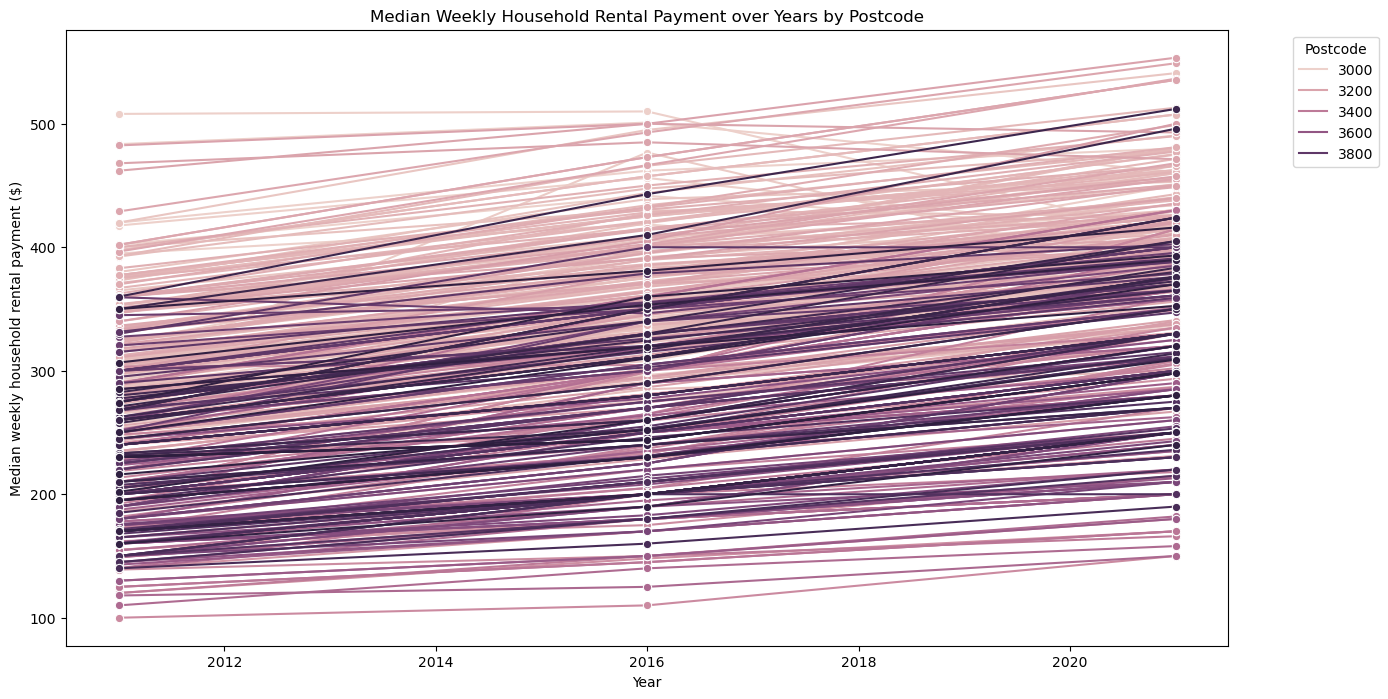

In [20]:
plt.figure(figsize=(15, 8))  # Set the figure size
sns.lineplot(data=combined_df, x='Year', y='Median weekly household rental payment ($)', hue='Postcode', marker='o')
plt.title('Median Weekly Household Rental Payment over Years by Postcode')
plt.legend(title='Postcode', bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot

plt.savefig("../plots/preliminary_linear_analysis.png")

In [49]:
top_bottom_df["Postcode"] = top_bottom_df["Postcode"].astype(str)

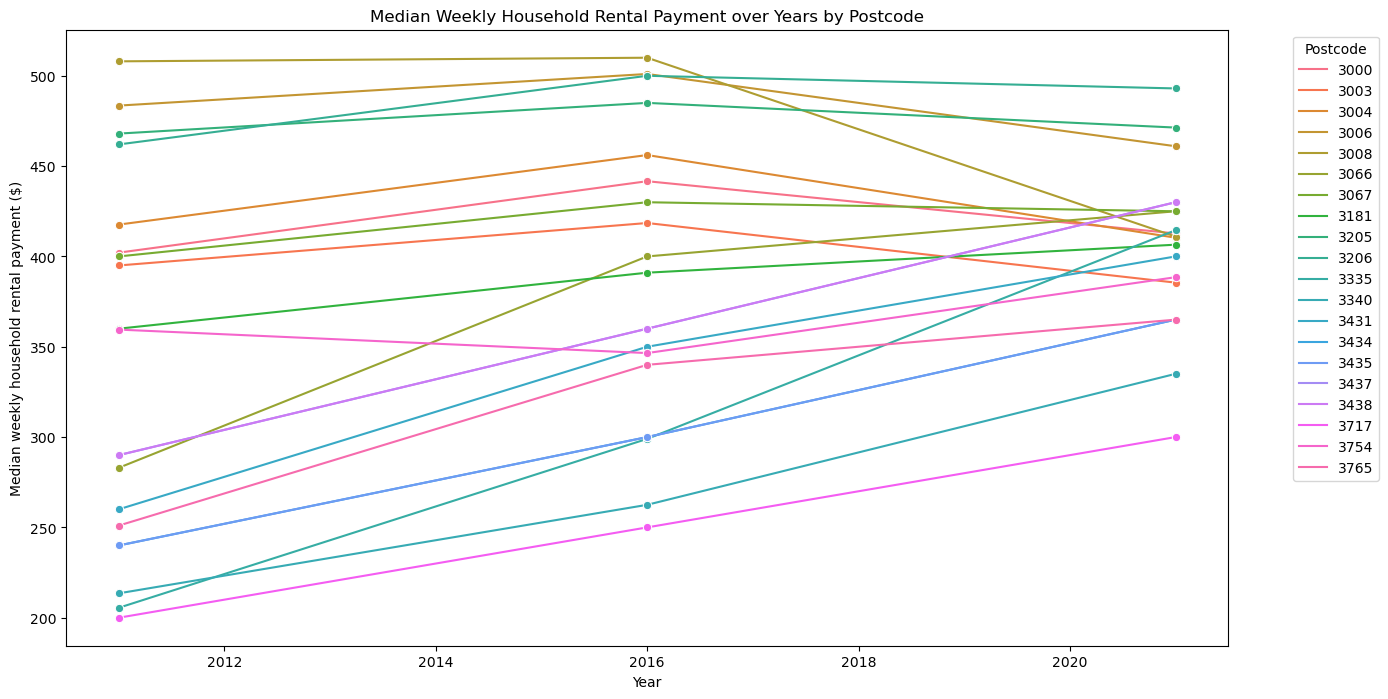

In [50]:
plt.figure(figsize=(15, 8))  # Set the figure size
sns.lineplot(data=top_bottom_df, x='Year', y='Median weekly household rental payment ($)', hue='Postcode', marker='o')
plt.title('Median Weekly Household Rental Payment over Years by Postcode')
plt.legend(title='Postcode', bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot
plt.show()